# Notebook corrigé — 29 algorithmes de Machine Learning

Ce notebook conserve les 29 algorithmes et leurs exemples. Les cellules de code ont été réorganisées pour mieux respecter les consignes : démonstration synthétique Q0, séparation entraînement/validation/test, prétraitement sans fuite d'information, expériences sur jeux publics réels et tableaux comparatifs.

**Important :** les jeux `Diabetes`, `Breast Cancer`, `Wine` et `Digits` utilisés dans les expériences finales sont des jeux publics réels fournis par scikit-learn. La cellule Q0 utilise séparément des données synthétiques générées pour illustrer leur structure ; elles ne sont jamais présentées comme des données réelles.

## Organisation du notebook

- **Q0 :** générer, afficher et visualiser des données synthétiques de démonstration.
- **Algorithmes 1 à 29 :** conserver les exemples, corriger les pipelines et afficher des métriques pertinentes.
- **Q5 à Q8 :** documenter les jeux de données publics, préparer les données sans fuite, comparer des méthodes de référence et avancées.

Les sections théoriques Q1 à Q4 (présentation, schéma conceptuel, contextes d'utilisation et commentaire rédigé) doivent être rédigées sous chaque titre d'algorithme ; elles ne sont pas remplacées par du code.

## Partie A — Questions communes à traiter pour chaque algorithme (1 à 29)

Sous chaque titre d'algorithme, ajouter les quatre sous-sections Markdown demandées : `Présentation`, `Schéma explicatif`, `Contextes d'utilisation` et `Analyse de l'expérience Python`. Les cellules de code ci-dessous fournissent les sorties nécessaires à l'analyse.

## Partie B — Expérimentation finale sur des données publiques

Les expériences finales utilisent des données publiques réelles, adaptées à chaque famille. Les transformations apprises sont ajustées sur l'entraînement pour les tâches supervisées. Pour les méthodes non supervisées, l'analyse porte explicitement sur les observations disponibles et les étiquettes éventuelles ne servent qu'à l'évaluation externe.

## Partie C — Restitution

Les résultats numériques doivent être obtenus en exécutant les cellules dans Google Colab. Ne pas recopier des valeurs supposées. Les cellules finales construisent des tableaux comparatifs et des figures ; la discussion écrite des résultats et des limites reste à rédiger.

In [45]:
# Installation des bibliothèques nécessaires dans Google Colab
!pip -q install -U scikit-learn xgboost umap-learn gymnasium[toy-text] pandas matplotlib seaborn
# Environnement tiers public de bandit compatible Gymnasium (Q25-Q26)
!pip -q install git+https://github.com/foreverska/buffalo-gym.git

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [46]:
# Imports, chargement des jeux publics réels et séparation sans fuite d'information
import sys, platform, warnings
from datetime import date
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.datasets import load_diabetes, load_breast_cancer, load_wine, load_digits
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error, mean_squared_error, r2_score,
    f1_score, precision_score, recall_score, balanced_accuracy_score,
    accuracy_score, roc_auc_score, silhouette_score, adjusted_rand_score
)
from sklearn.preprocessing import StandardScaler, PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.dummy import DummyRegressor, DummyClassifier
from sklearn.base import clone

GRAINE = 42
np.random.seed(GRAINE)

# 1) Régression : Diabetes (jeu public réel)
jeu_reg = load_diabetes(as_frame=True)
X_reg = jeu_reg.data
# Cible : progression quantitative de la maladie un an après les mesures initiales
y_reg = jeu_reg.target

# 2) Classification : Breast Cancer Wisconsin Diagnostic (jeu public réel)
jeu_cls = load_breast_cancer(as_frame=True)
X_cls = jeu_cls.data
y_cls = jeu_cls.target

# 3) Clustering/anomalies : Wine Recognition (jeu public réel)
jeu_groupes = load_wine(as_frame=True)
X_clu = jeu_groupes.data.to_numpy(dtype=float)  # caractéristiques originales, pas une ACP préalable
y_wine = jeu_groupes.target.to_numpy()          # réservé à l'évaluation externe

# 4) Réduction de dimension : Digits (jeu public réel de chiffres manuscrits)
jeu_images = load_digits()
X_images = jeu_images.data.astype(float)
y_digits = jeu_images.target

# Découpage 60 % entraînement, 20 % validation, 20 % test pour les tâches supervisées
Xr_trainval, Xr_test, yr_trainval, yr_test = train_test_split(
    X_reg, y_reg, test_size=0.20, random_state=GRAINE
)
Xr_ent, Xr_val, yr_ent, yr_val = train_test_split(
    Xr_trainval, yr_trainval, test_size=0.25, random_state=GRAINE
)
Xc_trainval, Xc_test, yc_trainval, yc_test = train_test_split(
    X_cls, y_cls, test_size=0.20, stratify=y_cls, random_state=GRAINE
)
Xc_ent, Xc_val, yc_ent, yc_val = train_test_split(
    Xc_trainval, yc_trainval, test_size=0.25, stratify=yc_trainval, random_state=GRAINE
)

# Fonctions communes d'évaluation : les hyperparamètres ne sont pas réglés sur le test.
def eval_regression(modele, nom):
    modele.fit(Xr_ent, yr_ent)
    lignes = []
    for nom_split, X, y in [('Validation', Xr_val, yr_val), ('Test', Xr_test, yr_test)]:
        pred = modele.predict(X)
        lignes.append({
            'Modèle': nom, 'Jeu': nom_split,
            'MAE': mean_absolute_error(y, pred),
            'RMSE': mean_squared_error(y, pred) ** 0.5,
            'R2': r2_score(y, pred)
        })
    resultat = pd.DataFrame(lignes)
    display(resultat.round(4))
    return modele

def eval_classification(modele, nom):
    modele.fit(Xc_ent, yc_ent)
    lignes = []
    for nom_split, X, y in [('Validation', Xc_val, yc_val), ('Test', Xc_test, yc_test)]:
        pred = modele.predict(X)
        ligne = {
            'Modèle': nom, 'Jeu': nom_split,
            'F1_macro': f1_score(y, pred, average='macro'),
            'Précision_macro': precision_score(y, pred, average='macro', zero_division=0),
            'Rappel_macro': recall_score(y, pred, average='macro', zero_division=0),
            'Balanced_accuracy': balanced_accuracy_score(y, pred)
        }
        if hasattr(modele, 'predict_proba') and len(np.unique(y)) == 2:
            try:
                ligne['ROC_AUC'] = roc_auc_score(y, modele.predict_proba(X)[:, 1])
            except Exception:
                ligne['ROC_AUC'] = np.nan
        lignes.append(ligne)
    display(pd.DataFrame(lignes).round(4))
    return modele

print('Versions : Python', platform.python_version(), '| NumPy', np.__version__,
      '| Pandas', pd.__version__, '| scikit-learn', sklearn.__version__)
print('Diabetes :', X_reg.shape, '| Breast Cancer :', X_cls.shape,
      '| Wine :', X_clu.shape, '| Digits :', X_images.shape)
print('Découpage régression :', len(Xr_ent), 'train /', len(Xr_val), 'validation /', len(Xr_test), 'test')
print('Découpage classification :', len(Xc_ent), 'train /', len(Xc_val), 'validation /', len(Xc_test), 'test')

Versions : Python 3.13.18 | NumPy 2.4.6 | Pandas 3.1.1 | scikit-learn 1.9.1
Diabetes : (442, 10) | Breast Cancer : (569, 30) | Wine : (178, 13) | Digits : (1797, 64)
Découpage régression : 264 train / 89 validation / 89 test
Découpage classification : 341 train / 114 validation / 114 test


Régression synthétique : (120, 2) (120,)
Classification synthétique : (120, 2) (120,)
Clustering synthétique : (120, 2) (120,)
Aperçu des données synthétiques de régression :


,Variable_1,Variable_2,Cible
0,0.651391,0.954002,38.367200
1,-0.299007,0.087047,2.837422
2,2.720169,-0.264657,-1.043268
3,-1.913280,0.241962,16.795999
4,-0.857158,0.625667,21.649715


Aperçu classification :


,Variable_1,Variable_2,Classe
0,1.623267,1.303451,1
1,0.164329,0.540942,1
2,1.450453,0.765794,1
3,1.975872,-1.648082,0
4,0.055241,-0.569659,0


Aperçu clustering :


,Variable_1,Variable_2,Groupe
0,-3.084207,8.791495,0
1,-2.525394,7.745033,0
2,-3.724595,9.391383,0
3,-1.534167,10.641774,0
4,-7.257950,-5.969347,2


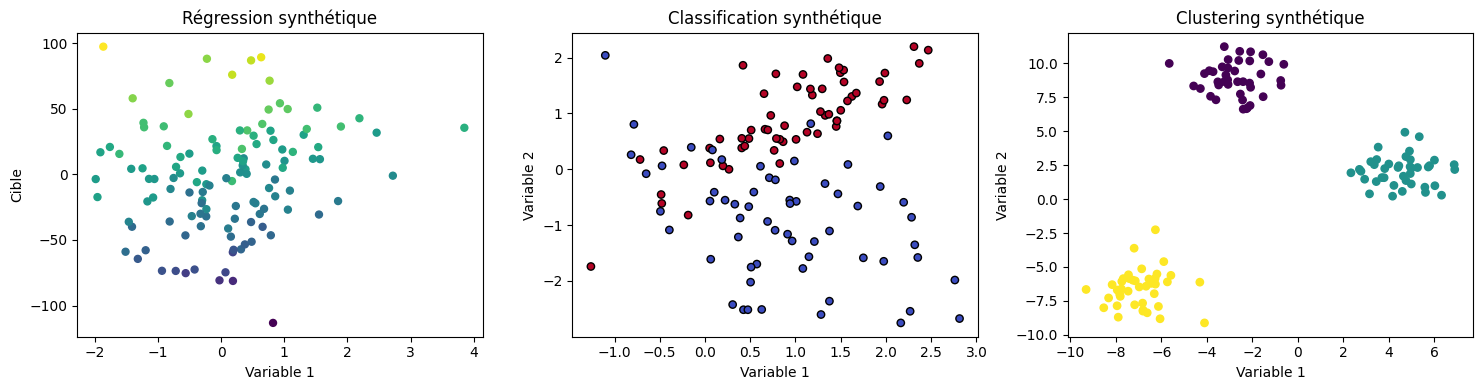

In [47]:
# Q0 — Génération, récupération, affichage et visualisation de données synthétiques
# Ces données servent uniquement à comprendre la forme des entrées ; elles ne sont PAS les jeux réels Q5-Q8.
from sklearn.datasets import make_regression, make_classification, make_blobs

X_syn_reg, y_syn_reg = make_regression(n_samples=120, n_features=2, noise=12, random_state=GRAINE)
X_syn_cls, y_syn_cls = make_classification(n_samples=120, n_features=2, n_informative=2,
                                           n_redundant=0, n_clusters_per_class=1,
                                           random_state=GRAINE)
X_syn_clu, y_syn_clu = make_blobs(n_samples=120, centers=3, n_features=2,
                                 cluster_std=1.2, random_state=GRAINE)

print('Régression synthétique :', X_syn_reg.shape, y_syn_reg.shape)
print('Classification synthétique :', X_syn_cls.shape, y_syn_cls.shape)
print('Clustering synthétique :', X_syn_clu.shape, y_syn_clu.shape)

# Afficher un extrait récupéré sous forme de DataFrame
syn_reg_df = pd.DataFrame(X_syn_reg, columns=['Variable_1', 'Variable_2'])
syn_reg_df['Cible'] = y_syn_reg
print('Aperçu des données synthétiques de régression :')
display(syn_reg_df.head())
syn_cls_df = pd.DataFrame(X_syn_cls, columns=['Variable_1', 'Variable_2'])
syn_cls_df['Classe'] = y_syn_cls
syn_clu_df = pd.DataFrame(X_syn_clu, columns=['Variable_1', 'Variable_2'])
syn_clu_df['Groupe'] = y_syn_clu
print('Aperçu classification :'); display(syn_cls_df.head())
print('Aperçu clustering :'); display(syn_clu_df.head())

# Exemple de visualisation des trois tâches synthétiques
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].scatter(X_syn_reg[:, 0], y_syn_reg, c=X_syn_reg[:, 1], cmap='viridis', s=25)
axes[0].set_title('Régression synthétique'); axes[0].set_xlabel('Variable 1'); axes[0].set_ylabel('Cible')
axes[1].scatter(X_syn_cls[:, 0], X_syn_cls[:, 1], c=y_syn_cls, cmap='coolwarm', edgecolor='k', s=28)
axes[1].set_title('Classification synthétique'); axes[1].set_xlabel('Variable 1'); axes[1].set_ylabel('Variable 2')
axes[2].scatter(X_syn_clu[:, 0], X_syn_clu[:, 1], c=y_syn_clu, cmap='viridis', s=28)
axes[2].set_title('Clustering synthétique'); axes[2].set_xlabel('Variable 1'); axes[2].set_ylabel('Variable 2')
plt.tight_layout(); plt.show()

## 1. Régression linéaire

**Question ciblée (Partie B) :** Expliquez pourquoi une relation linéaire entre les variables médicales et la cible peut être insuffisante.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [48]:
# 1. Régression linéaire — paramètres estimés sur l'entraînement uniquement
from sklearn.linear_model import LinearRegression
modele = make_pipeline(StandardScaler(), LinearRegression())
eval_regression(modele, 'Régression linéaire')

,Modèle,Jeu,MAE,RMSE,R2
0,Régression linéaire,Validation,42.9389,51.1937,0.5216
1,Régression linéaire,Test,42.9245,54.1564,0.4464


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 2. Ridge

**Question ciblée (Partie B) :** Que se passe-t-il lorsque la pénalisation L2 devient très forte ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [49]:
# 2. Ridge — alpha contrôle la pénalisation L2
from sklearn.linear_model import Ridge
modele = make_pipeline(StandardScaler(), Ridge(alpha=25.0))
eval_regression(modele, 'Ridge (alpha=25)')

,Modèle,Jeu,MAE,RMSE,R2
0,Ridge (alpha=25),Validation,42.7065,51.2029,0.5215
1,Ridge (alpha=25),Test,42.8852,53.7168,0.4554


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('ridge', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 3. Lasso

**Question ciblée (Partie B) :** Comment la pénalisation L1 sélectionne-t-elle des variables ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [50]:
# 3. Lasso — alpha contrôle la pénalisation L1 et peut annuler certains coefficients
from sklearn.linear_model import Lasso
modele = make_pipeline(StandardScaler(), Lasso(alpha=3.0, max_iter=20000, random_state=GRAINE))
eval_regression(modele, 'Lasso (alpha=3)')

,Modèle,Jeu,MAE,RMSE,R2
0,Lasso (alpha=3),Validation,42.6807,51.0378,0.5246
1,Lasso (alpha=3),Test,42.6034,52.8287,0.4732


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('lasso', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 4. Régression polynomiale

**Question ciblée (Partie B) :** Quelle difficulté pose la croissance du nombre de caractéristiques polynomiales ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [51]:
# 4. Régression polynomiale — toutes les transformations sont apprises dans le pipeline
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import Ridge
modele = make_pipeline(
    StandardScaler(), PolynomialFeatures(degree=2, include_bias=False),
    StandardScaler(), Ridge(alpha=60.0)
)
eval_regression(modele, 'Polynomiale degré 2 + Ridge')

,Modèle,Jeu,MAE,RMSE,R2
0,Polynomiale degré 2 + Ridge,Validation,43.7203,53.7393,0.4729
1,Polynomiale degré 2 + Ridge,Test,41.0973,52.1390,0.4869


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler-1', ...), ('polynomialfeatures', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](10,)","['age','sex','bmi',...,'s4','s5','s6']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,10
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


## 5. Arbre de régression

**Question ciblée (Partie B) :** Pourquoi limiter la profondeur et le nombre minimal d’observations par feuille ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [52]:
# 5. Arbre de régression — aucune standardisation nécessaire pour les arbres
from sklearn.tree import DecisionTreeRegressor
modele = DecisionTreeRegressor(max_depth=3, min_samples_leaf=8, random_state=GRAINE)
eval_regression(modele, 'Arbre de régression')

,Modèle,Jeu,MAE,RMSE,R2
0,Arbre de régression,Validation,48.2275,60.0210,0.3425
1,Arbre de régression,Test,47.1600,59.2669,0.3370


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.For an example of how ``max_depth`` influences the model, see:ref:`sphx_glr_auto_examples_tree_plot_tree_regression.py`.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",8
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 0.24 Poisson deviance criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``

## 6. Forêt aléatoire — régression

**Question ciblée (Partie B) :** Décrivez le bootstrap et expliquez le rôle de la moyenne des arbres.

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [53]:
# 6. Forêt aléatoire — agrégation de plusieurs arbres
from sklearn.ensemble import RandomForestRegressor
modele = RandomForestRegressor(n_estimators=120, min_samples_leaf=4,
                               random_state=GRAINE, n_jobs=-1)
eval_regression(modele, 'Forêt aléatoire régression')

,Modèle,Jeu,MAE,RMSE,R2
0,Forêt aléatoire régression,Validation,43.9001,53.8297,0.4711
1,Forêt aléatoire régression,Test,43.9122,54.1400,0.4468


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",120
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",4
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""squared_error"", ""absolute_error"", ""poisson""}, default=""squared_error""The function to measure the quality of a split. Supported criteriaare ""squared_error"" for the mean squared error, which is equal tovariance reduction as feature selection criterion and minimizes the L2loss using the mean of each terminal node, ""absolute_error"" for the meanabsolute error, which minimizes the L1 loss using the median of each terminalnode, and ""poisson"" which uses reduction in Poisson deviance to find splits,also using the mean of each terminal node... versionadded:: 0.18 Mean Absolute Error (MAE) criterion... versionadded:: 1.0 Poisson criterion... versionchanged:: 1.9 Criterion `""friedman_mse""` was deprecated.",'squared_error'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=1.0The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None or 1.0, then `max_features=n_features`... note:: The default of 1.0 is equivalent to bagged trees and more randomness can be achieved by setting smaller values, e.g. 0.3... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to 1.0.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",1.0
,"m

## 7. Gradient Boosting — régression

**Question ciblée (Partie B) :** Pourquoi les arbres sont-ils entraînés séquentiellement dans le boosting ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [54]:
# 7. Gradient Boosting — arbres ajoutés séquentiellement
from sklearn.ensemble import HistGradientBoostingRegressor
modele = HistGradientBoostingRegressor(max_iter=110, max_leaf_nodes=12,
                                       random_state=GRAINE)
eval_regression(modele, 'HistGradientBoosting régression')

,Modèle,Jeu,MAE,RMSE,R2
0,HistGradientBoosting régression,Validation,45.5550,57.5159,0.3962
1,HistGradientBoosting régression,Test,45.9278,56.8458,0.3901


,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees.",110
,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",12
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'squared_error', 'absolute_error', 'gamma', 'poisson', 'quantile'}, default='squared_error'The loss function to use in the boosting process. Note that the""squared error"", ""gamma"" and ""poisson"" losses actually implement""half least squares loss"", ""half gamma deviance"" and ""half poissondeviance"" to simplify the computation of the gradient. Furthermore,""gamma"" and ""poisson"" losses internally use a log-link, ""gamma""requires ``y > 0`` and ""poisson"" requires ``y >= 0``.""quantile"" uses the pinball loss... versionchanged:: 0.23 Added option 'poisson'... versionchanged:: 1.1 Added option 'quantile'... versionchanged:: 1.3 Added option 'gamma'.",'squared_error'
,"quantile quantile: float, default=NoneIf loss is ""quantile"", this parameter specifies which quantile to be estimatedand must be between 0 and 1.",None
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255


## 8. Régression logistique

**Question ciblée (Partie B) :** Comment interpréter une probabilité prédite et ajuster le seuil de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [55]:
# 8. Régression logistique — F1 macro pour tenir compte des deux classes
from sklearn.linear_model import LogisticRegression
modele = make_pipeline(StandardScaler(), LogisticRegression(C=0.2, max_iter=2000,
                                                             random_state=GRAINE))
eval_classification(modele, 'Régression logistique')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,Régression logistique,Validation,0.9716,0.9797,0.9651,0.9651,0.998
1,Régression logistique,Test,0.9716,0.9741,0.9692,0.9692,0.996


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 9. KNN

**Question ciblée (Partie B) :** Quel est l’effet d’une distance normalisée et du nombre de voisins ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [56]:
# 9. K plus proches voisins — la standardisation est essentielle pour les distances
from sklearn.neighbors import KNeighborsClassifier
modele = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=9, weights='distance'))
eval_classification(modele, 'KNN (k=9)')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,KNN (k=9),Validation,0.9422,0.961,0.9302,0.9302,0.9951
1,KNN (k=9),Test,0.9713,0.980,0.9643,0.9643,0.9917


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('kneighborsclassifier', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 10. Naive Bayes

**Question ciblée (Partie B) :** Quelle hypothèse d’indépendance conditionnelle est faite par Naive Bayes ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [57]:
# 10. Naive Bayes gaussien — hypothèse de distributions gaussiennes conditionnelles
from sklearn.naive_bayes import GaussianNB
modele = GaussianNB(var_smoothing=1e-8)
eval_classification(modele, 'Naive Bayes gaussien')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,Naive Bayes gaussien,Validation,0.9343,0.9365,0.9324,0.9324,0.9876
1,Naive Bayes gaussien,Test,0.9521,0.9605,0.9454,0.9454,0.9871


,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-08
,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[127.,214.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.37,0.63]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,0.003287
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,30
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 30)","[[ 17.32, 21.72,114.56,..., 0.19, 0.33, 0.09], [ 12.08, 17.68, 77.67,..., 0.07, 0.27, 0.08]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 30)","[[ 11.2 , 18.05,521.64,..., 0.01, 0.01, 0. ], [ 3.19, 15.78,140.2 ,..., 0. , 0.01, 0. ]]"


## 11. Arbre de décision

**Question ciblée (Partie B) :** Comment calculer l’impureté de Gini et choisir une séparation ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [58]:
# 11. Arbre de décision — profondeur limitée pour réduire le surapprentissage
from sklearn.tree import DecisionTreeClassifier
modele = DecisionTreeClassifier(max_depth=3, min_samples_leaf=5, random_state=GRAINE)
eval_classification(modele, 'Arbre de décision')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,Arbre de décision,Validation,0.9435,0.9482,0.9394,0.9394,0.9548
1,Arbre de décision,Test,0.9435,0.9435,0.9435,0.9435,0.9886


,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",3
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in

## 12. Forêt aléatoire — classification

**Question ciblée (Partie B) :** Pourquoi une forêt est-elle généralement moins instable qu’un arbre seul ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [59]:
# 12. Forêt aléatoire — classification
from sklearn.ensemble import RandomForestClassifier
modele = RandomForestClassifier(n_estimators=110, max_depth=6,
                                random_state=GRAINE, n_jobs=-1)
eval_classification(modele, 'Forêt aléatoire classification')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,Forêt aléatoire classification,Validation,0.9531,0.9554,0.9510,0.9510,0.9840
1,Forêt aléatoire classification,Test,0.9435,0.9435,0.9435,0.9435,0.9924


,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",110
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",6
,"n_jobs n_jobs: int, default=NoneThe number of jobs to run in parallel. :meth:`fit`, :meth:`predict`,:meth:`decision_path` and :meth:`apply` are all parallelized over thetrees. ``None`` means 1 unless in a :obj:`joblib.parallel_backend`context. ``-1`` means using all processors. See :term:`Glossary<n_jobs>` for more details.",-1
,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total nu

## 13. SVM

**Question ciblée (Partie B) :** À quoi servent les vecteurs de support et le paramètre C ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [60]:
# 13. SVM à noyau RBF — standardisation intégrée au pipeline
from sklearn.svm import SVC
modele = make_pipeline(StandardScaler(), SVC(kernel='rbf', C=2.0, gamma='scale', probability=True))
eval_classification(modele, 'SVM RBF')

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:236: FutureWarning: The `probability` parameter was deprecated in 1.9 and will be removed in version 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`
  warnings.warn(


,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,SVM RBF,Validation,0.9906,0.9931,0.9884,0.9884,0.9977
1,SVM RBF,Test,0.9812,0.9812,0.9812,0.9812,0.9960


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('svc', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](30,)","['mean radius','mean texture','mean perimeter',...,'worst concave points', 'worst symmetry','worst fractal dimension']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,30
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


## 14. Gradient Boosting — classification

**Question ciblée (Partie B) :** Comment corriger progressivement les erreurs de classification ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [61]:
# 14. Gradient Boosting pour la classification
from sklearn.ensemble import HistGradientBoostingClassifier
modele = HistGradientBoostingClassifier(max_iter=100, max_leaf_nodes=10,
                                         random_state=GRAINE)
eval_classification(modele, 'HistGradientBoosting classification')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,HistGradientBoosting classification,Validation,0.9627,0.9627,0.9627,0.9627,0.9892
1,HistGradientBoosting classification,Test,0.9343,0.9324,0.9365,0.9365,0.9917


,"max_leaf_nodes max_leaf_nodes: int or None, default=31The maximum number of leaves for each tree. Must be strictly greaterthan 1. If None, there is no maximum limit.",10
,"random_state random_state: int, RandomState instance or None, default=NonePseudo-random number generator to control the subsampling in thebinning process, and the train/validation data split if early stoppingis enabled.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"loss loss: {'log_loss'}, default='log_loss'The loss function to use in the boosting process.For binary classification problems, 'log_loss' is also known as logistic loss,binomial deviance or binary crossentropy. Internally, the model fits one treeper boosting iteration and uses the logistic sigmoid function (expit) asinverse link function to compute the predicted positive class probability.For multiclass classification problems, 'log_loss' is also known as multinomialdeviance or categorical crossentropy. Internally, the model fits one tree perboosting iteration and per class and uses the softmax function as inverse linkfunction to compute the predicted probabilities of the classes.",'log_loss'
,"learning_rate learning_rate: float, default=0.1The learning rate, also known as *shrinkage*. This is used as amultiplicative factor for the leaves values. Use ``1`` for noshrinkage.",0.1
,"max_iter max_iter: int, default=100The maximum number of iterations of the boosting process, i.e. themaximum number of trees for binary classification. For multiclassclassification, `n_classes` trees per iteration are built.",100
,"max_depth max_depth: int or None, default=NoneThe maximum depth of each tree. The depth of a tree is the number ofedges to go from the root to the deepest leaf.Depth isn't constrained by default.",None
,"min_samples_leaf min_samples_leaf: int, default=20The minimum number of samples per leaf. For small datasets with lessthan a few hundred samples, it is recommended to lower this valuesince only very shallow trees would be built.",20
,"l2_regularization l2_regularization: float, default=0The L2 regularization parameter penalizing leaves with small hessians.Use ``0`` for no regularization (default).",0.0
,"max_features max_features: float, default=1.0Proportion of randomly chosen features in each and every node split.This is a form of regularization, smaller values make the trees weakerlearners and might prevent overfitting.If interaction constraints from `interaction_cst` are present, only allowedfeatures are taken into account for the subsampling... versionadded:: 1.4",1.0
,"max_bins max_bins: int, default=255The maximum number of bins to use for non-missing values. Beforetraining, each feature of the input array `X` is binned intointeger-valued bins, which allows for a much faster training stage.Features with a small number of unique values may use less than``max_bins`` bins. In addition to the ``max_bins`` bins, one more binis always reserved for missing values. Must be no larger than 255.",255
,"categorical_features categorical_features: array-like of {bool, int, str} of shape (n_features) or shape (n_categorical_features,), default='from_dtype'Indicates the categorical features.- None : no feature will be considered categorical.- boolean array-like : boolean mask indicating categorical features.- integer array-like : integer indices indicating categorical features.- str array-like: names of categorical features (assuming the training data has feature names).- `""from_dtype""`: dataframe columns with dtype ""Categorical"" and ""Enum"" are considered to be categorical features. The input must be a dataframe that is supported by narwhals (or supports it): :func:`narwhals.from_native` must work. This is the case, for instance, for pandas and polars DataFrames.For each categorical feature, there must be at most `max_bins` uniquecategories. Negative values for categorical features encoded as numericdtypes are treated as missing val

## 15. AdaBoost

**Question ciblée (Partie B) :** Comment AdaBoost repondère-t-il les exemples difficiles ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [62]:
# 15. AdaBoost — apprentissage séquentiel avec pondération des observations
from sklearn.ensemble import AdaBoostClassifier
modele = AdaBoostClassifier(n_estimators=90, learning_rate=0.7, random_state=GRAINE)
eval_classification(modele, 'AdaBoost')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,AdaBoost,Validation,0.9623,0.9673,0.9581,0.9581,0.9980
1,AdaBoost,Test,0.9337,0.9360,0.9315,0.9315,0.9888


,"n_estimators n_estimators: int, default=50The maximum number of estimators at which boosting is terminated.In case of perfect fit, the learning procedure is stopped early.Values must be in the range `[1, inf)`.",90
,"learning_rate learning_rate: float, default=1.0Weight applied to each classifier at each boosting iteration. A higherlearning rate increases the contribution of each classifier. There isa trade-off between the `learning_rate` and `n_estimators` parameters.Values must be in the range `(0.0, inf)`.",0.7
,"random_state random_state: int, RandomState instance or None, default=NoneControls the random seed given at each `estimator` at eachboosting iteration.Thus, it is only used when `estimator` exposes a `random_state`.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",42
,"estimator estimator: object, default=NoneThe base estimator from which the boosted ensemble is built.Support for sample weighting is required, as well as proper``classes_`` and ``n_classes_`` attributes. If ``None``, thenthe base estimator is :class:`~sklearn.tree.DecisionTreeClassifier`initialized with `max_depth=1`... versionadded:: 1.2 `base_estimator` was renamed to `estimator`.",None
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels.","ndarray[int64](2,)","[0,1]"
estimator_ estimator_: estimatorThe base estimator from which the ensemble is grown... versionadded:: 1.2 `base_estimator_` was renamed to `estimator_`.,DecisionTreeClassifier,DecisionTreeC...r(max_depth=1)
estimator_errors_ estimator_errors_: ndarray of floatsClassification error for each estimator in the boostedensemble.,"ndarray[float64](90,)","[0.07,0.1 ,0.22,...,0.36,0.45,0.36]"
estimator_weights_ estimator_weights_: ndarray of floatsWeights for each estimator in the boosted ensemble.,"ndarray[float64](90,)","[1.78,1.55,0.87,...,0.39,0.15,0.4 ]"
estimators_ estimators_: list of classifiersThe collection of fitted sub-estimators.,list,"[DecisionTreeC...te=1608637542), DecisionTreeC...te=1273642419), DecisionTreeC...te=1935803228), DecisionTreeC...ate=787846414), ...]"
"feature_importances_ feature_importances_: ndarray of shape (n_features,)The impurity-based feature importances if supported by the``estimator`` (when based on decision trees).Warning: impurity-based feature importances can be misleading forhigh cardinality features (many unique values). See:func:`sklearn.inspection.permutation_importance` as an alternative.","ndarray[float64](30,)","[0. ,0.05,0. ,...,0.13,0.02,0.01]"


## 16. XGBoost

**Question ciblée (Partie B) :** Quel est le rôle de la régularisation et du learning_rate dans XGBoost ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [63]:
# 16. XGBoost — modèle avancé ; n_jobs limité pour une exécution reproductible
from xgboost import XGBClassifier
modele = XGBClassifier(n_estimators=100, max_depth=2, learning_rate=0.09,
                       random_state=GRAINE, eval_metric='logloss',
                       n_jobs=1, tree_method='hist')
eval_classification(modele, 'XGBoost')

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy,ROC_AUC
0,XGBoost,Validation,0.9531,0.9554,0.9510,0.9510,0.9915
1,XGBoost,Test,0.9440,0.9403,0.9484,0.9484,0.9907


,"base_score base_score: typing.Union[float, typing.List[float], NoneType]The initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.Optional[typing.List[xgboost.callback.TrainingCallback]]List of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API <callback_api>`... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: typing.Optional[float]Subsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: typing.Optional[float]Subsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: typing.Optional[float]Subsample ratio of columns when constructing each tree.,None
,"device device: typing.Optional[str].. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: typing.Optional[int].. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,True
,"eval_metric eval_metric: typing.Union[str, typing.List[typing.Union[str, typing.Callable]], typing.Callable, NoneType].. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_method=""hist"", eval_metric=mean_absolute_error, ) reg.fit(X, y, eval_set=[(X, y)])",'logloss'
,feature_types feature_types: typing.Optional[typing.Sequence[str]].. versionadded:: 1.7.0Used for specifying feature types without constructing a dataframe. Seethe :py:class:`DMatrix` for details.,None


## 17. K-means

**Question ciblée (Partie B) :** Comment affecter chaque vin à son centroïde puis recalculer celui-ci ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Silhouette : 0.2849
ARI externe (étiquettes Wine non utilisées à l’apprentissage) : 0.8975


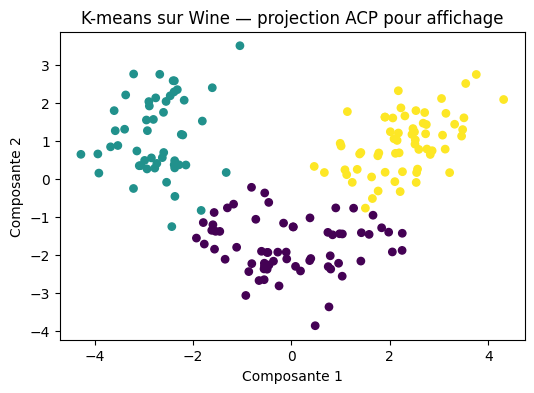

In [64]:
# 17. K-means — standardisation des variables avant calcul des distances
from sklearn.cluster import KMeans
X_clu_scaled = StandardScaler().fit_transform(X_clu)
modele = KMeans(n_clusters=3, n_init=20, random_state=GRAINE).fit(X_clu_scaled)
labels_kmeans = modele.labels_
print('Silhouette :', round(silhouette_score(X_clu_scaled, labels_kmeans), 4))
print('ARI externe (étiquettes Wine non utilisées à l’apprentissage) :', round(adjusted_rand_score(y_wine, labels_kmeans), 4))
projection_wine = __import__('sklearn.decomposition', fromlist=['PCA']).PCA(n_components=2, random_state=GRAINE).fit_transform(X_clu_scaled)
plt.figure(figsize=(6, 4)); plt.scatter(projection_wine[:, 0], projection_wine[:, 1], c=labels_kmeans, cmap='viridis', s=28)
plt.title('K-means sur Wine — projection ACP pour affichage'); plt.xlabel('Composante 1'); plt.ylabel('Composante 2'); plt.show()

## 18. Classification hiérarchique

**Question ciblée (Partie B) :** Que montre un dendrogramme et comment définit-on le lien de Ward ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [65]:
# 18. Classification hiérarchique — linkage de Ward sur données standardisées
from sklearn.cluster import AgglomerativeClustering
etiquettes = AgglomerativeClustering(n_clusters=3, linkage='ward').fit_predict(X_clu_scaled)
print('Silhouette :', round(silhouette_score(X_clu_scaled, etiquettes), 4))
print('ARI externe :', round(adjusted_rand_score(y_wine, etiquettes), 4))

Silhouette : 0.2774
ARI externe : 0.7899


## 19. DBSCAN

**Question ciblée (Partie B) :** À quoi correspondent les points marqués comme bruit par DBSCAN ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [66]:
# 19. DBSCAN — eps et min_samples déterminent les voisinages et le bruit
from sklearn.cluster import DBSCAN
modele = DBSCAN(eps=2.2, min_samples=5)
etiquettes = modele.fit_predict(X_clu_scaled)
masque = etiquettes != -1
nb_groupes = len(set(etiquettes[masque]))
print('Groupes détectés :', nb_groupes, '| Observations bruit :', int((~masque).sum()))
if nb_groupes >= 2 and masque.sum() > nb_groupes:
    print('Silhouette (hors bruit) :', round(silhouette_score(X_clu_scaled[masque], etiquettes[masque]), 4))
else:
    print('Silhouette non calculée : DBSCAN doit produire au moins deux groupes non vides.')

Groupes détectés : 2 | Observations bruit : 55
Silhouette (hors bruit) : 0.348


## 20. Mélanges gaussiens

**Question ciblée (Partie B) :** En quoi les appartenances probabilistes diffèrent-elles d’une affectation dure ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [67]:
# 20. Mélange gaussien — affectations probabilistes puis classe la plus probable
from sklearn.mixture import GaussianMixture
modele = GaussianMixture(n_components=3, covariance_type='full', random_state=GRAINE,
                         n_init=5, reg_covar=1e-5).fit(X_clu_scaled)
etiquettes = modele.predict(X_clu_scaled)
print('Poids des composantes :', modele.weights_.round(3))
print('Silhouette :', round(silhouette_score(X_clu_scaled, etiquettes), 4))
print('ARI externe :', round(adjusted_rand_score(y_wine, etiquettes), 4))

Poids des composantes : [0.356 0.358 0.286]
Silhouette : 0.2844
ARI externe : 0.8804


## 21. ACP

**Question ciblée (Partie B) :** Que mesure la variance expliquée par les deux axes de l’ACP ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Variance expliquée par axe : [0.1203 0.0956]
Variance cumulée des deux axes : 0.2159


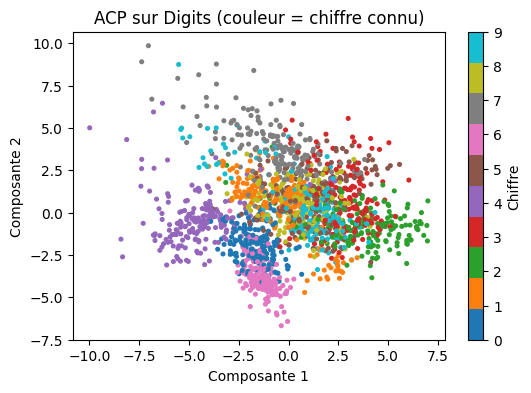

In [68]:
# 21. ACP — réduction de dimension sur les pixels Digits standardisés
from sklearn.decomposition import PCA
X_images_scaled = StandardScaler().fit_transform(X_images)  # analyse non supervisée descriptive
modele = PCA(n_components=2, random_state=GRAINE)
projection = modele.fit_transform(X_images_scaled)
print('Variance expliquée par axe :', modele.explained_variance_ratio_.round(4))
print('Variance cumulée des deux axes :', round(modele.explained_variance_ratio_.sum(), 4))
plt.figure(figsize=(6, 4)); plt.scatter(projection[:, 0], projection[:, 1], c=y_digits, cmap='tab10', s=7)
plt.title('ACP sur Digits (couleur = chiffre connu)'); plt.xlabel('Composante 1'); plt.ylabel('Composante 2'); plt.colorbar(label='Chiffre'); plt.show()

## 22. t-SNE

**Question ciblée (Partie B) :** Pourquoi la distance entre groupes éloignés peut-elle être trompeuse en t-SNE ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

Trustworthiness (voisinage local) : 0.9863


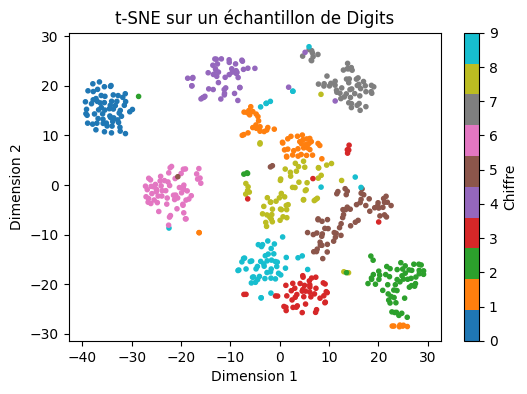

In [69]:
# 22. t-SNE — visualisation locale ; les distances globales entre amas ne sont pas interprétables
from sklearn.manifold import TSNE, trustworthiness
rng = np.random.default_rng(GRAINE)
idx_digits = np.sort(rng.choice(len(X_images_scaled), size=600, replace=False))
X_tsne = X_images_scaled[idx_digits]
projection = TSNE(n_components=2, perplexity=30, random_state=GRAINE,
                  init='pca', learning_rate='auto').fit_transform(X_tsne)
print('Trustworthiness (voisinage local) :', round(trustworthiness(X_tsne, projection, n_neighbors=5), 4))
plt.figure(figsize=(6, 4)); plt.scatter(projection[:, 0], projection[:, 1], c=y_digits[idx_digits], cmap='tab10', s=9)
plt.title('t-SNE sur un échantillon de Digits'); plt.xlabel('Dimension 1'); plt.ylabel('Dimension 2'); plt.colorbar(label='Chiffre'); plt.show()

## 23. UMAP

**Question ciblée (Partie B) :** Quel est l’effet de n_neighbors et min_dist sur les voisinages ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


Trustworthiness : 0.9726


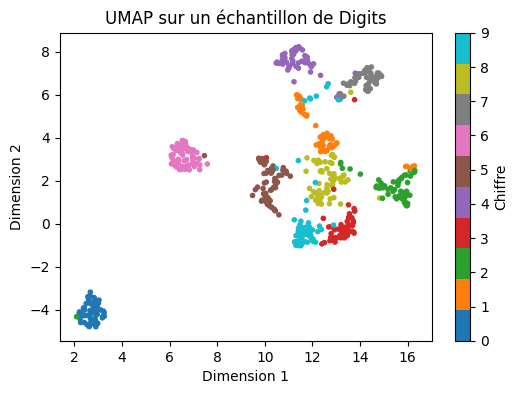

In [70]:
# 23. UMAP — réduction non linéaire ; nécessite le paquet umap-learn
import umap
from sklearn.manifold import trustworthiness
rng = np.random.default_rng(GRAINE)
idx_umap = np.sort(rng.choice(len(X_images_scaled), size=600, replace=False))
X_umap = X_images_scaled[idx_umap]
projection = umap.UMAP(n_components=2, n_neighbors=20, min_dist=0.15,
                       random_state=GRAINE, transform_seed=GRAINE).fit_transform(X_umap)
print('Trustworthiness :', round(trustworthiness(X_umap, projection, n_neighbors=5), 4))
plt.figure(figsize=(6, 4)); plt.scatter(projection[:, 0], projection[:, 1], c=y_digits[idx_umap], cmap='tab10', s=9)
plt.title('UMAP sur un échantillon de Digits'); plt.xlabel('Dimension 1'); plt.ylabel('Dimension 2'); plt.colorbar(label='Chiffre'); plt.show()

## 24. Isolation Forest

**Question ciblée (Partie B) :** Pourquoi une observation statistiquement atypique n’est-elle pas forcément une erreur ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [71]:
# 24. Isolation Forest — aucune étiquette d'anomalie fiable n'est fournie avec Wine
from sklearn.ensemble import IsolationForest
modele = make_pipeline(StandardScaler(), IsolationForest(contamination=0.05,
                       n_estimators=150, random_state=GRAINE))
modele.fit(X_clu)
pred_anomalies = modele.predict(X_clu)
indices = np.where(pred_anomalies == -1)[0]
print('Nombre de vins signalés atypiques :', len(indices))
print('Indices (extrait) :', indices[:12])
print('Aucune précision/rappel n’est calculée : il n’existe pas ici de vérité terrain fiable pour les anomalies.')

Nombre de vins signalés atypiques : 9
Indices (extrait) : [ 59  69  73  95 110 121 124 146 158]
Aucune précision/rappel n’est calculée : il n’existe pas ici de vérité terrain fiable pour les anomalies.


## 25. Bandits manchots

**Question ciblée (Partie B) :** Comment calculer une estimation du gain moyen de chaque bras ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [72]:
# 25. Bandit manchot — environnement tiers public Buffalo-Gym compatible Gymnasium
# Les récompenses sont générées par interaction avec l'environnement, pas lues depuis un CSV.
import gymnasium as gym
import buffalo_gym

def run_bandit_random_or_round_robin(n_steps=1500, seed=GRAINE):
    env = gym.make('Buffalo-v0')
    obs, info = env.reset(seed=seed)
    n_arms = env.action_space.n
    sums = np.zeros(n_arms); counts = np.zeros(n_arms, dtype=int)
    rewards = []
    for t in range(n_steps):
        arm = t % n_arms  # exploration équilibrée pour estimer chaque bras
        obs, reward, terminated, truncated, info = env.step(int(arm))
        sums[arm] += reward; counts[arm] += 1; rewards.append(reward)
        if terminated or truncated:
            obs, info = env.reset()
    env.close()
    estimates = sums / np.maximum(counts, 1)
    print('Nombre de bras :', n_arms)
    print('Nombre de sélections par bras :', counts)
    print('Récompense moyenne estimée par bras :', estimates.round(3))
    print('Récompense moyenne cumulée :', round(float(np.mean(rewards)), 3))
    return estimates, counts, rewards

estimations_bandit, comptes_bandit, recompenses_bandit = run_bandit_random_or_round_robin()

/usr/local/lib/python3.13/dist-packages/gymnasium/utils/passive_env_checker.py:243: UserWarning: WARN: The infos returned by `reset` and the following `step` share an object, therefore, modifying one will modify the other. Environments should return new info data on every call as users commonly keep the data returned to them.
  logger.warn(
/usr/local/lib/python3.13/dist-packages/gymnasium/utils/passive_env_checker.py:243: UserWarning: WARN: The infos returned by `step` and the following `step` share an object, therefore, modifying one will modify the other. Environments should return new info data on every call as users commonly keep the data returned to them.
  logger.warn(


Nombre de bras : 10
Nombre de sélections par bras : [150 150 150 150 150 150 150 150 150 150]
Récompense moyenne estimée par bras : [7.72  3.067 3.436 0.455 6.593 3.295 3.142 0.431 2.342 2.709]
Récompense moyenne cumulée : 3.319


## 26. Epsilon-greedy

**Question ciblée (Partie B) :** Quelle différence entre exploration aléatoire et exploitation du meilleur bras estimé ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [73]:
# 26. Epsilon-greedy — comparaison avec exploration équilibrée sur le même environnement public
import gymnasium as gym
import buffalo_gym

def run_epsilon_greedy(n_steps=3000, epsilon=0.10, seed=GRAINE):
    env = gym.make('Buffalo-v0')
    obs, info = env.reset(seed=seed)
    rng = np.random.default_rng(seed)
    n_arms = env.action_space.n
    sums = np.zeros(n_arms); counts = np.zeros(n_arms, dtype=int)
    rewards = []
    for t in range(n_steps):
        estimates = sums / np.maximum(counts, 1)
        if rng.random() < epsilon:
            arm = int(rng.integers(n_arms))
        else:
            # Départage aléatoire en cas d'égalité des estimations
            meilleurs = np.flatnonzero(estimates == estimates.max())
            arm = int(rng.choice(meilleurs))
        obs, reward, terminated, truncated, info = env.step(arm)
        counts[arm] += 1; sums[arm] += reward; rewards.append(reward)
        if terminated or truncated:
            obs, info = env.reset()
    env.close()
    print('Epsilon :', epsilon, '| Comptes :', counts)
    print('Estimations des récompenses :', (sums / np.maximum(counts, 1)).round(3))
    print('Récompense moyenne :', round(float(np.mean(rewards)), 3))
    return rewards, counts

rewards_epsilon, counts_epsilon = run_epsilon_greedy()

Epsilon : 0.1 | Comptes : [1473   31   37   28  415   31   26  428   27  504]
Estimations des récompenses : [4.574 2.759 3.267 2.2   4.522 3.123 3.62  4.527 2.873 9.808]
Récompense moyenne : 5.344


## 27. Q-learning

**Question ciblée (Partie B) :** Comment calculer une cible de Bellman dans Taxi et pourquoi le max intervient-il ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [74]:
# 27. Q-learning — Taxi-v4 ; entraînement puis évaluation gloutonne sur épisodes distincts
import gymnasium as gym

def train_q_learning(seed, episodes=2500, alpha=0.2, gamma=0.96):
    env = gym.make('Taxi-v4')
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        epsilon = max(0.05, 1.0 - episode / (episodes * 0.8))
        for _ in range(200):
            if rng.random() < epsilon:
                action = int(rng.integers(env.action_space.n))
            else:
                action = int(np.argmax(Q[state]))
            next_state, reward, terminated, truncated, _ = env.step(action)
            target = reward if terminated else reward + gamma * np.max(Q[next_state])
            Q[state, action] += alpha * (target - Q[state, action])
            state = next_state
            if terminated or truncated:
                break
    env.close()
    return Q

def evaluate_taxi_policy(Q, seed, episodes=100):
    env = gym.make('Taxi-v4')
    returns, successes = [], []
    for ep in range(episodes):
        state, _ = env.reset(seed=seed + 10000 + ep)
        total = 0; success = False
        for _ in range(200):
            action = int(np.argmax(Q[state]))
            state, reward, terminated, truncated, _ = env.step(action)
            total += reward
            if terminated:
                success = (reward > 0)
                break
            if truncated:
                break
        returns.append(total); successes.append(success)
    env.close()
    return float(np.mean(returns)), float(np.mean(successes))

q_learning_results = []
for seed in [11, 22, 33, 44, 55]:
    Q_seed = train_q_learning(seed)
    reward_moy, taux_reussite = evaluate_taxi_policy(Q_seed, seed)
    q_learning_results.append({'Algorithme': 'Q-learning', 'Graine': seed,
                               'Récompense moyenne': reward_moy, 'Taux de réussite': taux_reussite})
q_learning_df = pd.DataFrame(q_learning_results)
display(q_learning_df.round(3))
print('Taille de la table Q :', Q_seed.shape)

,Algorithme,Graine,Récompense moyenne,Taux de réussite
0,Q-learning,11,7.93,1.0
1,Q-learning,22,7.96,1.0
2,Q-learning,33,8.05,1.0
3,Q-learning,44,8.01,1.0
4,Q-learning,55,8.18,1.0


Taille de la table Q : (500, 6)


## 28. SARSA

**Question ciblée (Partie B) :** Pourquoi SARSA met-il à jour Q avec l’action suivante réellement choisie ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [75]:
# 28. SARSA — même environnement, même nombre de graines et protocole comparable
import gymnasium as gym

def train_sarsa(seed, episodes=2500, alpha=0.2, gamma=0.96):
    env = gym.make('Taxi-v4')
    rng = np.random.default_rng(seed)
    Q = np.zeros((env.observation_space.n, env.action_space.n))
    def choose_action(state, epsilon):
        if rng.random() < epsilon:
            return int(rng.integers(env.action_space.n))
        return int(np.argmax(Q[state]))
    for episode in range(episodes):
        state, _ = env.reset(seed=seed + episode)
        epsilon = max(0.05, 1.0 - episode / (episodes * 0.8))
        action = choose_action(state, epsilon)
        for _ in range(200):
            next_state, reward, terminated, truncated, _ = env.step(action)
            next_action = choose_action(next_state, epsilon)
            target = reward if terminated else reward + gamma * Q[next_state, next_action]
            Q[state, action] += alpha * (target - Q[state, action])
            state, action = next_state, next_action
            if terminated or truncated:
                break
    env.close()
    return Q

sarsa_results = []
for seed in [11, 22, 33, 44, 55]:
    Q_seed = train_sarsa(seed)
    reward_moy, taux_reussite = evaluate_taxi_policy(Q_seed, seed)
    sarsa_results.append({'Algorithme': 'SARSA', 'Graine': seed,
                          'Récompense moyenne': reward_moy, 'Taux de réussite': taux_reussite})
sarsa_df = pd.DataFrame(sarsa_results)
display(sarsa_df.round(3))

,Algorithme,Graine,Récompense moyenne,Taux de réussite
0,SARSA,11,3.02,0.98
1,SARSA,22,-2.92,0.95
2,SARSA,33,3.51,0.98
3,SARSA,44,3.53,0.98
4,SARSA,55,5.82,0.99


## 29. DQN — cible conceptuelle

**Question ciblée (Partie B) :** Pourquoi un DQN complet a-t-il besoin d’un réseau cible et d’une mémoire de rejouement ?

**À compléter par le binôme :** présentation · schéma original · deux cas d’usage · analyse de la sortie et variation d’un hyperparamètre.

In [76]:
# 29. DQN — illustration conceptuelle de la cible de Bellman (pas d'entraînement de réseau)
# La consigne précise qu'une expérience DQN complète est facultative : cette cellule reste conceptuelle.
recompenses = np.array([2.0, -1.0, 10.0, 0.0])
termine = np.array([False, False, True, False])
q_cible_etat_suivant = np.array([5.0, 3.0, 7.0, 2.0])
gamma = 0.9
cibles = recompenses + gamma * (~termine) * q_cible_etat_suivant
print('Cibles de Bellman illustratives :', cibles)
print('Statut : DQN conceptuel uniquement ; aucun réseau neuronal n’a été entraîné.')
print('Un DQN complet nécessiterait un réseau en ligne, un réseau cible et une mémoire de rejouement.')

Cibles de Bellman illustratives : [ 6.5  1.7 10.   1.8]
Statut : DQN conceptuel uniquement ; aucun réseau neuronal n’a été entraîné.
Un DQN complet nécessiterait un réseau en ligne, un réseau cible et une mémoire de rejouement.


## Annexes — Implémentations manuelles (Partie B)

Reproduire les principes de la descente de gradient et de K-means sans utiliser leurs estimateurs prédéfinis. Comparer les résultats aux références scikit-learn.

In [77]:
# Annexe — Descente de gradient manuelle comparée à LinearRegression sur les seules données d'entraînement
x_train = Xr_ent.iloc[:, 2].to_numpy(dtype=float)
x_val = Xr_val.iloc[:, 2].to_numpy(dtype=float)
x_test = Xr_test.iloc[:, 2].to_numpy(dtype=float)
mu, sigma = x_train.mean(), x_train.std()
x_train = (x_train - mu) / sigma
x_val = (x_val - mu) / sigma
x_test = (x_test - mu) / sigma
y_train = np.asarray(yr_ent)
poids = 0.0; biais = float(y_train.mean()); pas = 0.01
for iteration in range(3000):
    erreur = poids * x_train + biais - y_train
    poids -= pas * 2 * np.mean(erreur * x_train)
    biais -= pas * 2 * np.mean(erreur)
print('Paramètres manuels : poids =', round(poids, 3), '| biais =', round(biais, 3))
from sklearn.linear_model import LinearRegression
modele_ref = LinearRegression().fit(x_train.reshape(-1, 1), y_train)
print('Scikit-learn :', modele_ref.coef_.round(3), '| biais =', round(modele_ref.intercept_, 3))
print('RMSE test (gradient manuel) :', round(mean_squared_error(yr_test, poids*x_test+biais)**0.5, 3))
print('RMSE test (scikit-learn) :', round(mean_squared_error(yr_test, modele_ref.predict(x_test.reshape(-1,1)))**0.5, 3))

Paramètres manuels : poids = 46.947 | biais = 149.811
Scikit-learn : [46.947] | biais = 149.811
RMSE test (gradient manuel) : 63.834
RMSE test (scikit-learn) : 63.834


In [78]:
# Annexe — K-means manuel sur les variables Wine standardisées
valeurs = X_clu_scaled.copy(); k = 3; generateur = np.random.default_rng(GRAINE)
centroides = valeurs[generateur.choice(len(valeurs), size=k, replace=False)].copy()
for iteration in range(100):
    distances = ((valeurs[:, None, :] - centroides[None, :, :]) ** 2).sum(axis=2)
    groupes = distances.argmin(axis=1)
    nouveaux = np.array([
        valeurs[groupes == j].mean(axis=0) if np.any(groupes == j) else centroides[j]
        for j in range(k)
    ])
    if np.allclose(nouveaux, centroides):
        break
    centroides = nouveaux
inertie = np.sum((valeurs - centroides[groupes]) ** 2)
from sklearn.cluster import KMeans
reference = KMeans(n_clusters=k, n_init=20, random_state=GRAINE).fit(valeurs)
print('Inertie manuelle :', round(inertie, 3))
print('Inertie scikit-learn :', round(reference.inertia_, 3))
print('Note : les initialisations peuvent différer ; comparer aussi plusieurs répétitions.')

Inertie manuelle : 1277.928
Inertie scikit-learn : 1277.928
Note : les initialisations peuvent différer ; comparer aussi plusieurs répétitions.


Le **Q-learning tabulaire manuel** est présenté à la section 27 sur Taxi-v3, et **SARSA** à la section 28. Scikit-learn ne propose pas de Q-learning tabulaire équivalent. Comparer plutôt les deux méthodes avec les mêmes paramètres, graines, nombre d’épisodes et métriques de succès.

# Expérimentations finales Q5–Q8 — données publiques réelles et comparaison par famille

Les jeux ci-dessous sont des observations réelles diffusées publiquement et chargées depuis les jeux intégrés de scikit-learn. Les données synthétiques de Q0 ne sont pas utilisées dans cette partie. Les étiquettes de Wine et Digits sont réservées à l'évaluation externe ou à la coloration des graphiques.

In [79]:
# Q5 — Traçabilité des jeux de données publics
from datetime import date
provenance = pd.DataFrame([
    {'Jeu': 'Diabetes', 'Source/organisme': 'Scikit-learn (jeu Diabetes de Efron et al.)',
     'URL': 'https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html',
     'Taille': f'{X_reg.shape[0]} lignes × {X_reg.shape[1]} variables',
     'Colonnes/cible': '10 variables quantitatives ; cible = progression quantitative à un an',
     'Accès/licence': 'Jeu fourni avec scikit-learn ; consulter la source et les conditions de redistribution associées.',
     'Consulté le': date.today().isoformat()},
    {'Jeu': 'Breast Cancer Wisconsin Diagnostic', 'Source/organisme': 'UCI Machine Learning Repository / scikit-learn',
     'URL': 'https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic',
     'Taille': f'{X_cls.shape[0]} lignes × {X_cls.shape[1]} variables',
     'Colonnes/cible': '30 mesures numériques ; cible = diagnostic (malin/bénin)',
     'Accès/licence': 'Dépôt UCI public ; vérifier la licence/attribution affichée sur la fiche UCI au moment de réutiliser.',
     'Consulté le': date.today().isoformat()},
    {'Jeu': 'Wine Recognition', 'Source/organisme': 'UCI Machine Learning Repository / scikit-learn',
     'URL': 'https://archive.ics.uci.edu/dataset/109/wine',
     'Taille': f'{X_clu.shape[0]} lignes × {X_clu.shape[1]} variables',
     'Colonnes/cible': '13 mesures physico-chimiques ; classe de cultivar utilisée uniquement en évaluation externe',
     'Accès/licence': 'Dépôt UCI public ; vérifier la licence/attribution affichée sur la fiche UCI au moment de réutiliser.',
     'Consulté le': date.today().isoformat()},
    {'Jeu': 'Optical Recognition of Handwritten Digits (sous-ensemble 8×8)', 'Source/organisme': 'Scikit-learn, données issues de l’UCI Optical Recognition of Handwritten Digits',
     'URL': 'https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html',
     'Taille': f'{X_images.shape[0]} images × {X_images.shape[1]} pixels',
     'Colonnes/cible': '64 intensités de pixels ; chiffre manuscrit (0 à 9)',
     'Accès/licence': 'Jeu fourni avec scikit-learn ; consulter la source UCI et les conditions de redistribution associées.',
     'Consulté le': date.today().isoformat()}
])
display(provenance)

# Q6 — Diagnostic de qualité : types, valeurs manquantes, doublons et valeurs extrêmes
for nom, df in {
    'Diabetes': X_reg.copy(), 'Breast Cancer': X_cls.copy(),
    'Wine': pd.DataFrame(X_clu), 'Digits': pd.DataFrame(X_images)
}.items():
    print('\n---', nom, '---')
    print('Dimensions :', df.shape)
    print('Types :', df.dtypes.value_counts().to_dict())
    print('Valeurs manquantes :', int(df.isna().sum().sum()))
    print('Lignes dupliquées :', int(df.duplicated().sum()))
    numeriques = df.select_dtypes(include=np.number)
    q1, q3 = numeriques.quantile(0.25), numeriques.quantile(0.75)
    nb_extremes = int(((numeriques < (q1 - 1.5*(q3-q1))) | (numeriques > (q3 + 1.5*(q3-q1)))).sum().sum())
    print('Valeurs extrêmes selon la règle IQR (comptage indicatif) :', nb_extremes)
print('Répartition des classes Breast Cancer :')
display(pd.Series(y_cls).value_counts().rename_axis('Classe').to_frame('Effectif'))
print('Les pipelines supervisés ajustent le StandardScaler sur X_train seulement ; aucune statistique du test n’est utilisée pour apprendre le prétraitement.')

,Jeu,Source/organisme,URL,Taille,Colonnes/cible,Accès/licence,Consulté le
0,Diabetes,Scikit-learn (jeu Diabetes de Efron et al.),https://scikit-learn.org/stable/modules/genera...,442 lignes × 10 variables,10 variables quantitatives ; cible = progressi...,Jeu fourni avec scikit-learn ; consulter la so...,2026-11-10
1,Breast Cancer Wisconsin Diagnostic,UCI Machine Learning Repository / scikit-learn,https://archive.ics.uci.edu/dataset/17/breast+...,569 lignes × 30 variables,30 mesures numériques ; cible = diagnostic (ma...,Dépôt UCI public ; vérifier la licence/attribu...,2026-11-10
2,Wine Recognition,UCI Machine Learning Repository / scikit-learn,https://archive.ics.uci.edu/dataset/109/wine,178 lignes × 13 variables,13 mesures physico-chimiques ; classe de culti...,Dépôt UCI public ; vérifier la licence/attribu...,2026-11-10
3,Optical Recognition of Handwritten Digits (sou...,"Scikit-learn, données issues de l’UCI Optical ...",https://scikit-learn.org/stable/modules/genera...,1797 images × 64 pixels,64 intensités de pixels ; chiffre manuscrit (0...,Jeu fourni avec scikit-learn ; consulter la so...,2026-11-10



--- Diabetes ---
Dimensions : (442, 10)
Types : {dtype('float64'): 10}
Valeurs manquantes : 0
Lignes dupliquées : 0
Valeurs extrêmes selon la règle IQR (comptage indicatif) : 40

--- Breast Cancer ---
Dimensions : (569, 30)
Types : {dtype('float64'): 30}
Valeurs manquantes : 0
Lignes dupliquées : 0
Valeurs extrêmes selon la règle IQR (comptage indicatif) : 608

--- Wine ---
Dimensions : (178, 13)
Types : {dtype('float64'): 13}
Valeurs manquantes : 0
Lignes dupliquées : 0
Valeurs extrêmes selon la règle IQR (comptage indicatif) : 21

--- Digits ---
Dimensions : (1797, 64)
Types : {dtype('float64'): 64}
Valeurs manquantes : 0
Lignes dupliquées : 0
Valeurs extrêmes selon la règle IQR (comptage indicatif) : 3453
Répartition des classes Breast Cancer :


,Effectif
Classe,
1,357
0,212


Les pipelines supervisés ajustent le StandardScaler sur X_train seulement ; aucune statistique du test n’est utilisée pour apprendre le prétraitement.


,Modèle,Jeu,MAE,RMSE,R²
0,Référence (moyenne),Validation,64.1288,75.6392,-0.0443
1,Référence (moyenne),Test,63.5314,72.9002,-0.0031
2,Modèle avancé (HistGradientBoosting),Validation,45.5550,57.5159,0.3962
3,Modèle avancé (HistGradientBoosting),Test,45.9278,56.8458,0.3901


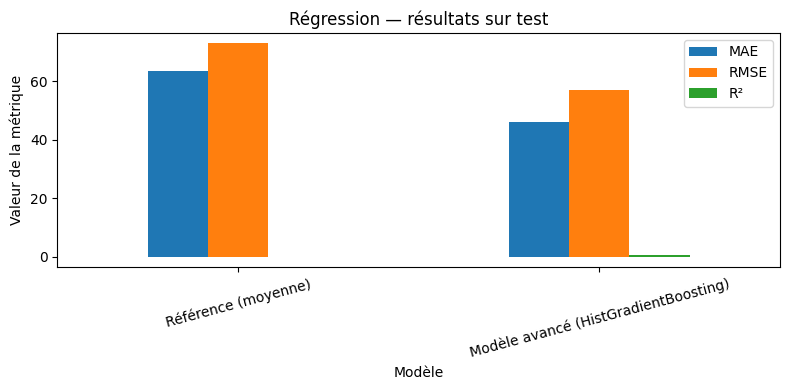

In [80]:
# Q8 — Comparaison régression : référence naïve vs modèle avancé
from sklearn.ensemble import HistGradientBoostingRegressor
reg_modeles = {
    'Référence (moyenne)': DummyRegressor(strategy='mean'),
    'Modèle avancé (HistGradientBoosting)': HistGradientBoostingRegressor(
        max_iter=110, max_leaf_nodes=12, random_state=GRAINE)
}
rows = []
for nom, modele in reg_modeles.items():
    modele.fit(Xr_ent, yr_ent)
    for split, X, y in [('Validation', Xr_val, yr_val), ('Test', Xr_test, yr_test)]:
        pred = modele.predict(X)
        rows.append({'Modèle': nom, 'Jeu': split,
                     'MAE': mean_absolute_error(y, pred),
                     'RMSE': mean_squared_error(y, pred)**0.5,
                     'R²': r2_score(y, pred)})
comparaison_reg = pd.DataFrame(rows)
display(comparaison_reg.round(4))
comparaison_reg[comparaison_reg['Jeu']=='Test'].set_index('Modèle')[['MAE','RMSE','R²']].plot(kind='bar', figsize=(8,4), title='Régression — résultats sur test')
plt.ylabel('Valeur de la métrique'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

,Modèle,Jeu,F1_macro,Précision_macro,Rappel_macro,Balanced_accuracy
0,Référence (classe majoritaire),Validation,0.3838,0.3114,0.5000,0.5000
1,Référence (classe majoritaire),Test,0.3871,0.3158,0.5000,0.5000
2,Modèle avancé (Random Forest),Validation,0.9531,0.9554,0.9510,0.9510
3,Modèle avancé (Random Forest),Test,0.9435,0.9435,0.9435,0.9435


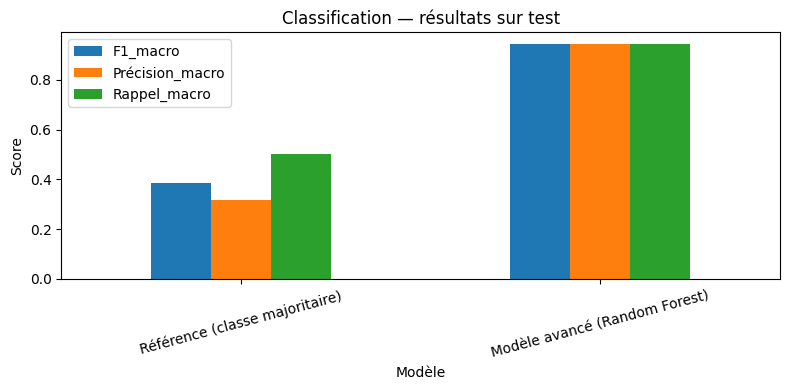

In [81]:
# Q8 — Comparaison classification : référence majoritaire vs Random Forest
from sklearn.ensemble import RandomForestClassifier
cls_modeles = {
    'Référence (classe majoritaire)': DummyClassifier(strategy='most_frequent'),
    'Modèle avancé (Random Forest)': make_pipeline(
        StandardScaler(), RandomForestClassifier(n_estimators=150, max_depth=6,
                                                 random_state=GRAINE, n_jobs=-1))
}
rows = []
for nom, modele in cls_modeles.items():
    modele.fit(Xc_ent, yc_ent)
    for split, X, y in [('Validation', Xc_val, yc_val), ('Test', Xc_test, yc_test)]:
        pred = modele.predict(X)
        rows.append({'Modèle': nom, 'Jeu': split,
                     'F1_macro': f1_score(y, pred, average='macro'),
                     'Précision_macro': precision_score(y, pred, average='macro', zero_division=0),
                     'Rappel_macro': recall_score(y, pred, average='macro', zero_division=0),
                     'Balanced_accuracy': balanced_accuracy_score(y, pred)})
comparaison_cls = pd.DataFrame(rows)
display(comparaison_cls.round(4))
comparaison_cls[comparaison_cls['Jeu']=='Test'].set_index('Modèle')[['F1_macro','Précision_macro','Rappel_macro']].plot(kind='bar', figsize=(8,4), title='Classification — résultats sur test')
plt.ylabel('Score'); plt.xticks(rotation=15); plt.tight_layout(); plt.show()

In [82]:
# Q8 — Comparaison clustering : K-means et hiérarchique ; labels Wine seulement en évaluation externe
from sklearn.cluster import KMeans, AgglomerativeClustering
X_wine_std = StandardScaler().fit_transform(X_clu)
cluster_modeles = {
    'K-means': KMeans(n_clusters=3, n_init=20, random_state=GRAINE),
    'Hiérarchique Ward': AgglomerativeClustering(n_clusters=3, linkage='ward')
}
rows = []
for nom, modele in cluster_modeles.items():
    labels = modele.fit_predict(X_wine_std)
    rows.append({'Méthode': nom,
                 'Silhouette (interne)': silhouette_score(X_wine_std, labels),
                 'ARI (externe, étiquettes réelles)': adjusted_rand_score(y_wine, labels),
                 'Nombre de groupes': len(np.unique(labels))})
display(pd.DataFrame(rows).round(4))

# Stabilité indicative de K-means selon plusieurs graines
stabilite = []
for seed in [1, 7, 21, 42, 84]:
    labels = KMeans(n_clusters=3, n_init=10, random_state=seed).fit_predict(X_wine_std)
    stabilite.append({'Graine': seed, 'Silhouette': silhouette_score(X_wine_std, labels),
                      'ARI vs classe réelle': adjusted_rand_score(y_wine, labels)})
display(pd.DataFrame(stabilite).round(4))

,Méthode,Silhouette (interne),"ARI (externe, étiquettes réelles)",Nombre de groupes
0,K-means,0.2849,0.8975,3
1,Hiérarchique Ward,0.2774,0.7899,3


,Graine,Silhouette,ARI vs classe réelle
0,1,0.2849,0.8975
1,7,0.2849,0.8975
2,21,0.2849,0.8975
3,42,0.2849,0.8975
4,84,0.2849,0.8975


ACP — variance expliquée cumulée (2 composantes) : 0.2159
t-SNE — trustworthiness : 0.9863


/usr/local/lib/python3.13/dist-packages/umap/umap_.py:4160: FutureWarning: compatibility_layout was not set, so UMAP is using the legacy (0.5.x) nearest-neighbor, initialization and layout pipeline. In a future release the default will change to compatibility_layout=False, which uses recursive initialization and the Adam optimizer and produces different embeddings. Set compatibility_layout=True to keep the current behavior and silence this warning, or compatibility_layout=False (or optimizer='adam') to adopt the new behavior now.
  self.fit(X, y, ensure_all_finite, **kwargs)
/usr/local/lib/python3.13/dist-packages/umap/umap_.py:3099: UserWarning: n_jobs value -1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP — trustworthiness : 0.9726


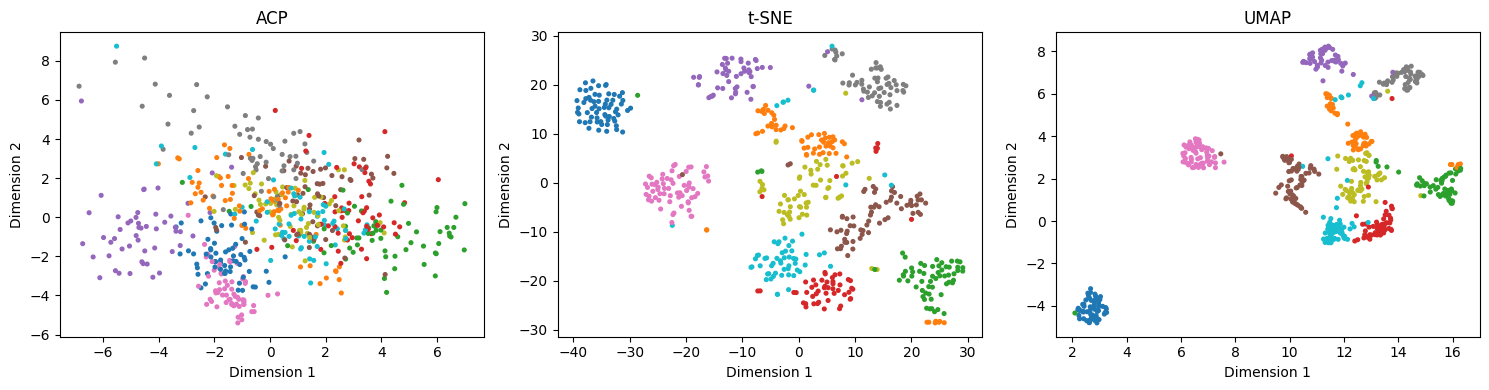

In [83]:
# Q8 — Réduction de dimension : variance expliquée (ACP) et conservation locale des voisinages
from sklearn.decomposition import PCA
from sklearn.manifold import trustworthiness
X_digits_std = StandardScaler().fit_transform(X_images)
pca_2 = PCA(n_components=2, random_state=GRAINE).fit_transform(X_digits_std)
pca_2_model = PCA(n_components=2, random_state=GRAINE).fit(X_digits_std)
print('ACP — variance expliquée cumulée (2 composantes) :', round(pca_2_model.explained_variance_ratio_.sum(), 4))

rng = np.random.default_rng(GRAINE)
idx = np.sort(rng.choice(len(X_digits_std), size=600, replace=False))
X_sample = X_digits_std[idx]
tsne_2 = TSNE(n_components=2, perplexity=30, random_state=GRAINE,
              init='pca', learning_rate='auto').fit_transform(X_sample)
print('t-SNE — trustworthiness :', round(trustworthiness(X_sample, tsne_2, n_neighbors=5), 4))
umap_2 = umap.UMAP(n_components=2, n_neighbors=20, min_dist=0.15,
                   random_state=GRAINE, transform_seed=GRAINE).fit_transform(X_sample)
print('UMAP — trustworthiness :', round(trustworthiness(X_sample, umap_2, n_neighbors=5), 4))
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, coords, titre in zip(axes, [pca_2[idx], tsne_2, umap_2], ['ACP', 't-SNE', 'UMAP']):
    ax.scatter(coords[:,0], coords[:,1], c=y_digits[idx], cmap='tab10', s=7)
    ax.set_title(titre); ax.set_xlabel('Dimension 1'); ax.set_ylabel('Dimension 2')
plt.tight_layout(); plt.show()

In [84]:
# Q8 — Détection d'anomalies : proportion d'alertes, sans métrique supervisée faute d'étiquettes fiables
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
X_wine_std = StandardScaler().fit_transform(X_clu)
iso = IsolationForest(contamination=0.05, random_state=GRAINE, n_estimators=150).fit(X_wine_std)
labels_iso = iso.predict(X_wine_std)
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.05)
labels_lof = lof.fit_predict(X_wine_std)
comparaison_anomalies = pd.DataFrame([
    {'Méthode': 'Isolation Forest', 'Observations signalées': int((labels_iso == -1).sum()),
     'Proportion alertes': float((labels_iso == -1).mean())},
    {'Méthode': 'Local Outlier Factor', 'Observations signalées': int((labels_lof == -1).sum()),
     'Proportion alertes': float((labels_lof == -1).mean())}
])
display(comparaison_anomalies.round(4))
print('Pas de précision/rappel : les données Wine ne fournissent pas de vérité terrain d’anomalies.')

,Méthode,Observations signalées,Proportion alertes
0,Isolation Forest,9,0.0506
1,Local Outlier Factor,9,0.0506


Pas de précision/rappel : les données Wine ne fournissent pas de vérité terrain d’anomalies.


Récompense moyenne        Taux de réussite       
                         mean    std             mean    std
Algorithme                                                  
Q-learning              8.026  0.098            1.000  0.000
SARSA                   2.592  3.268            0.976  0.015

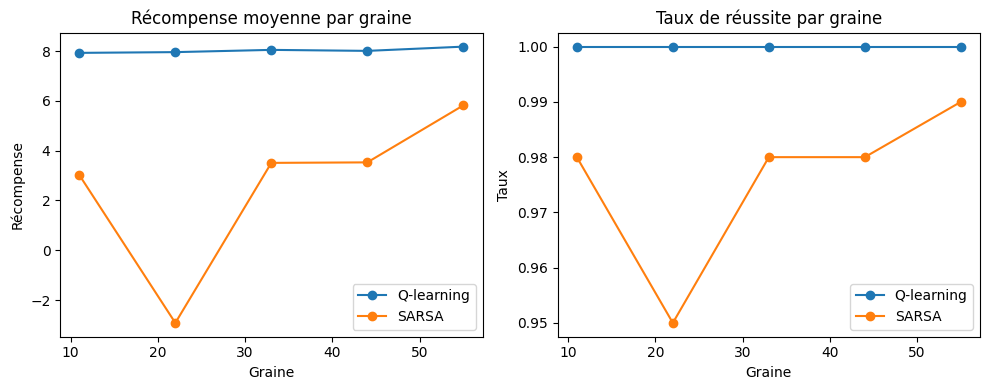

Les trajectoires Taxi-v3 sont générées par interaction avec un environnement Gymnasium ; ce ne sont pas des lignes d’un dataset réel.


In [85]:
# Q8 — Renforcement : comparaison Q-learning / SARSA sur Taxi-v3, plusieurs graines
rl_comparaison = pd.concat([q_learning_df, sarsa_df], ignore_index=True)
display(rl_comparaison.groupby('Algorithme')[['Récompense moyenne','Taux de réussite']].agg(['mean','std']).round(3))
fig, axes = plt.subplots(1, 2, figsize=(10,4))
for nom, groupe in rl_comparaison.groupby('Algorithme'):
    axes[0].plot(groupe['Graine'], groupe['Récompense moyenne'], marker='o', label=nom)
    axes[1].plot(groupe['Graine'], groupe['Taux de réussite'], marker='o', label=nom)
axes[0].set_title('Récompense moyenne par graine'); axes[0].set_xlabel('Graine'); axes[0].set_ylabel('Récompense')
axes[1].set_title('Taux de réussite par graine'); axes[1].set_xlabel('Graine'); axes[1].set_ylabel('Taux')
for ax in axes: ax.legend()
plt.tight_layout(); plt.show()
print('Les trajectoires Taxi-v3 sont générées par interaction avec un environnement Gymnasium ; ce ne sont pas des lignes d’un dataset réel.')

## Références techniques et provenance

- Diabetes (scikit-learn) : https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_diabetes.html
- Breast Cancer Wisconsin Diagnostic (UCI) : https://archive.ics.uci.edu/dataset/17/breast+cancer+wisconsin+diagnostic
- Wine Recognition (UCI) : https://archive.ics.uci.edu/dataset/109/wine
- Digits (scikit-learn) : https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_digits.html
- Gymnasium et environnements tiers : https://gymnasium.farama.org/environments/third_party_environments/
- Buffalo-Gym, environnement public de bandit compatible Gymnasium (licence MIT) : https://github.com/foreverska/buffalo-gym

**À vérifier avant remise :** consulter les fiches originales pour confirmer les conditions de réutilisation/attribution applicables à chaque jeu. Les dimensions affichées par le notebook correspondent aux versions réellement chargées par les fonctions scikit-learn.